Netflix Project

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 59.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 91.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
df = pd.read_csv('/content/netflix_titles.csv')

In [ ]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.shape

(8807, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Check categorical columns
df.select_dtypes(include='object').columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [ ]:
# Check numerical columns
df.select_dtypes(include='number').columns

Index(['release_year'], dtype='object')

In [ ]:
df.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


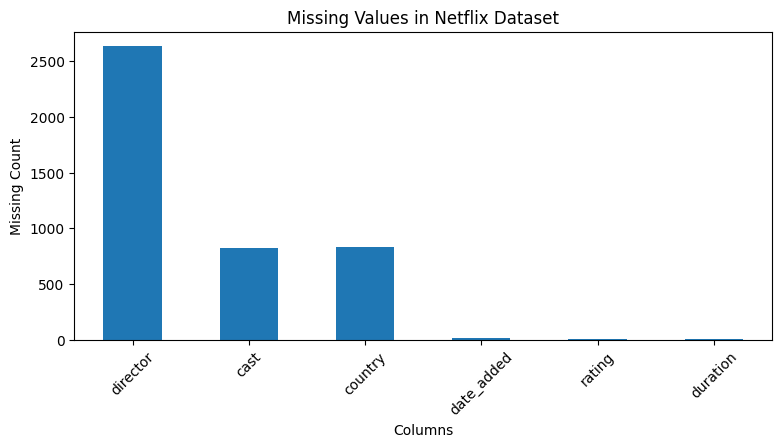

In [ ]:
missing = df.isnull().sum()

missing = missing[missing > 0]

missing.plot(kind='bar', figsize=(9, 4))

plt.title('Missing Values in Netflix Dataset')
plt.xlabel('Columns')
plt.ylabel('Missing Count')
plt.xticks(rotation=45)
plt.show()

# Check missing value percentages:
 (df.isnull().sum() / len(df)) * 100

Replacing / Cleaning

In [ ]:
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['rating'] = df['rating'].fillna('Unknown')
df['duration'] = df['duration'].fillna('Unknown')

# Alternative Way for missing value
df_test = df.copy()

# Mean example
df_test['release_year'] = df_test['release_year'].fillna(
    df_test['release_year'].mean()
)

# Mode example
df_test['rating'] = df_test['rating'].fillna(
    df_test['rating'].mode()[0]
)

# Forward fill example
df_test['country'] = df_test['country'].ffill()

# Backward fill example
df_test['director'] = df_test['director'].bfill()

In [ ]:
# Count duplicates
df.duplicated().sum()

# Remove duplicates
df = df.drop_duplicates()

# Verify
df.duplicated().sum()

np.int64(0)

In [ ]:
# Remove unwanted spaces from column names and text values.
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

In [ ]:
df['date_added'] = pd.to_datetime(
    df['date_added'],
    errors='coerce'
)

In [ ]:
df['year_added']=df['date_added'].dt.year
df['month_added']=df['date_added'].dt.month

In [ ]:
df.shape

df.info()

df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   object        
 1   type          8807 non-null   object        
 2   title         8807 non-null   object        
 3   director      8807 non-null   object        
 4   cast          8807 non-null   object        
 5   country       8807 non-null   object        
 6   date_added    8797 non-null   datetime64[ns]
 7   release_year  8807 non-null   int64         
 8   rating        8807 non-null   object        
 9   duration      8807 non-null   object        
 10  listed_in     8807 non-null   object        
 11  description   8807 non-null   object        
 12  year_added    8797 non-null   float64       
 13  month_added   8797 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(10)
memory usage: 963.4+ KB


,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,0


In [ ]:
df['type'].value_counts()

,count
type,
Movie,6131
TV Show,2676


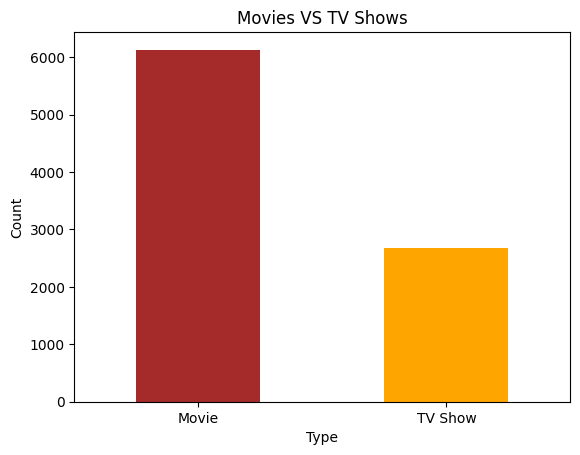

In [ ]:
import matplotlib.pyplot as plt

# Create a bar chart
df['type'].value_counts().plot(kind='bar', color=['brown', 'orange'])

plt.title('Movies VS TV Shows')
plt.xlabel('Type')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

Learn: Which type of content is available more on Netflix?

In [ ]:
df['country'].value_counts().head(10)

,count
country,
United States,2818
India,972
Unknown,831
United Kingdom,419
Japan,245
South Korea,199
Canada,181
Spain,145
France,124


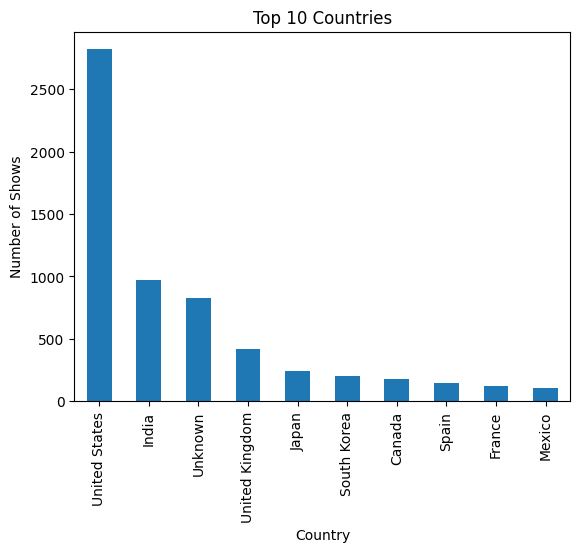

In [ ]:
df['country'].value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Countries')
plt.xlabel('Country')
plt.ylabel('Number of Shows')
plt.show()

Learn: Which country has produced the most Netflix content?

In [ ]:
df['year_added'].value_counts()

,count
year_added,
2019.0,2016
2020.0,1879
2018.0,1649
2021.0,1498
2017.0,1188
2016.0,429
2015.0,82
2014.0,24
2011.0,13


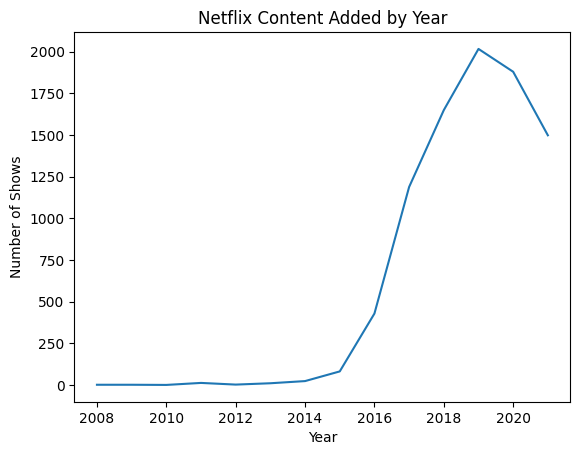

In [ ]:
df['year_added'].value_counts().sort_index().plot(kind='line')

plt.title('Netflix Content Added by Year')
plt.xlabel('Year')
plt.ylabel('Number of Shows')
plt.show()

Learn: In which year was the most content added to Netflix?

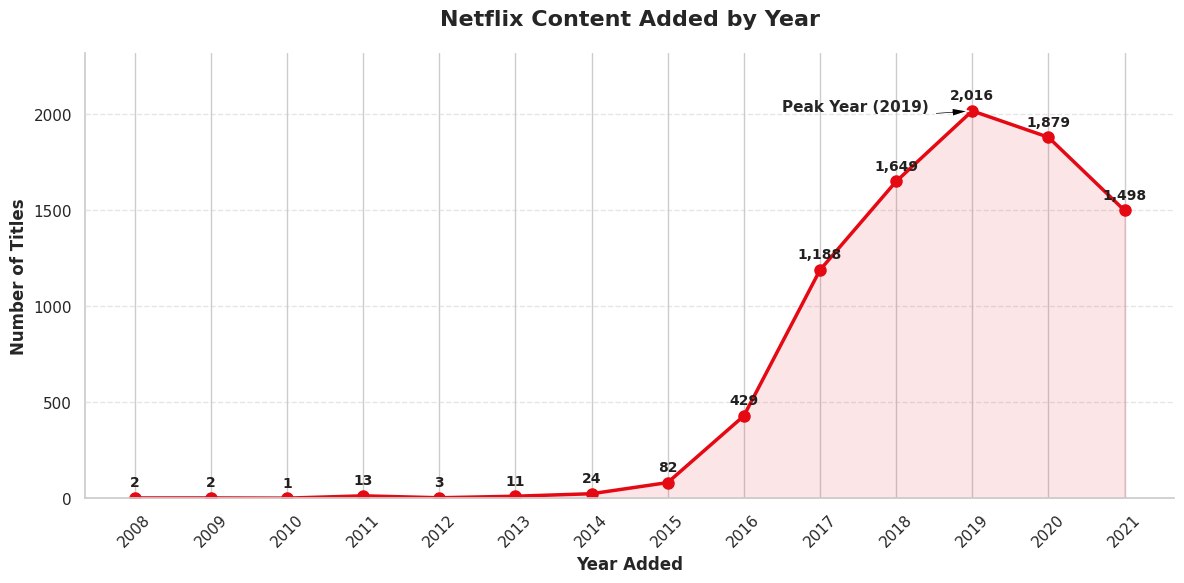

In [ ]:
# Advance graph
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare and sort the yearly counts
yearly_counts = df["year_added"].value_counts().sort_index()

# 2. Set visual theme and canvas size
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# 3. Plot the line with circular markers and brand styling
plt.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker="o",  # Adds dots at every year
    markersize=8,
    linewidth=2.5,
    color="#E50914",  # Netflix Red
    label="Total Titles Added",
)

# 4. Add a subtle shaded fill underneath the line
plt.fill_between(
    yearly_counts.index, yearly_counts.values, color="#E50914", alpha=0.1
)

# 5. Print the exact count above every dot
for year, count in zip(yearly_counts.index, yearly_counts.values):
    plt.text(
        year,
        count + (yearly_counts.max() * 0.03),  # Slightly above the dot
        f"{int(count):,}",  # Formats with comma (e.g., 2,016)
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#221F1F",
    )

# 6. Highlight the peak year with an arrow callout
peak_year = yearly_counts.idxmax()
peak_val = yearly_counts.max()
plt.annotate(
    f"Peak Year ({int(peak_year)})",
    xy=(peak_year, peak_val),
    xytext=(peak_year - 2.5, peak_val),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1.5, headwidth=6),
    fontsize=11,
    fontweight="bold",
)

# 7. Customize titles, axes, and borders
plt.title(
    "Netflix Content Added by Year", fontsize=16, fontweight="bold", pad=20
)
plt.xlabel("Year Added", fontsize=12, fontweight="bold")
plt.ylabel("Number of Titles", fontsize=12, fontweight="bold")

# Show every single year on the X-axis cleanly
plt.xticks(yearly_counts.index.astype(int), rotation=45)
plt.ylim(0, peak_val * 1.15)  # Adds breathing room at the top for text labels
plt.grid(axis="y", linestyle="--", alpha=0.5)
sns.despine()

plt.tight_layout()
plt.show()



# Key Details Added to Your Graph

• Point Markers (marker='o'): Places visible dots on each year so you can clearly see where each annual data point sits.

• Exact Value Labels (plt.text): Displays the formatted total count directly above every single point so readers do not have to guess values from the Y-axis.

• Shaded Area Fill (plt.fill_between): Adds a light red gradient under the curve to emphasize volume growth over time.

• Peak Year Callout (plt.annotate): Automatically finds the highest year in your dataset and points to it with a text arrow.

• Complete X-Axis Ticks (plt.xticks): Forces Matplotlib to display every year cleanly without skipping years or showing decimals (like 2018.5).


In [ ]:
df['rating'].value_counts().head(10)

,count
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


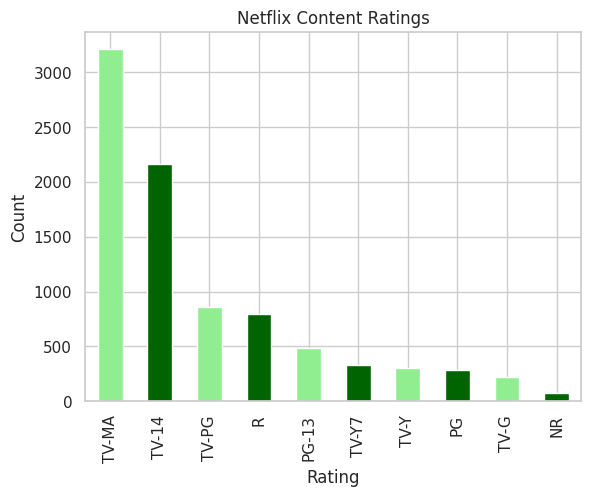

In [ ]:
df['rating'].value_counts().head(10).plot(kind='bar', color=['lightgreen', 'darkgreen'])


plt.title('Netflix Content Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

Learn: Which rating appears most frequently?

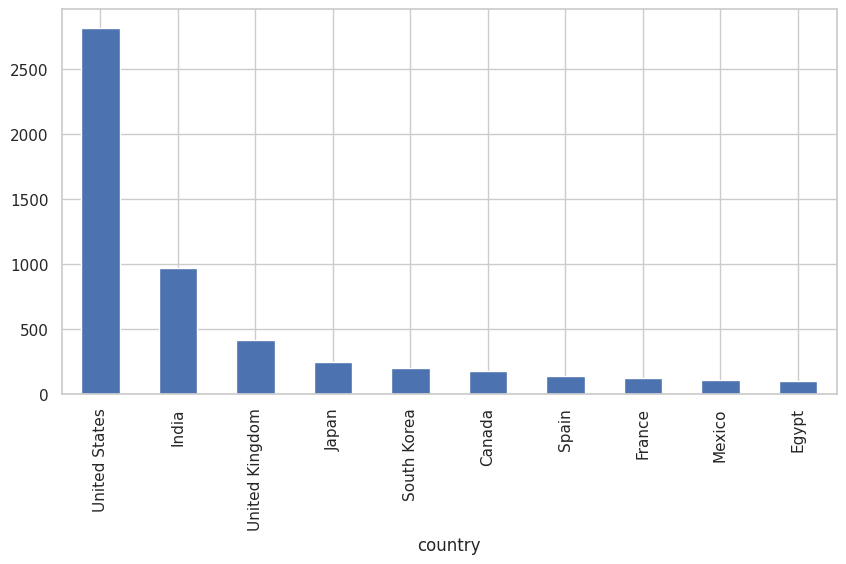

In [ ]:
plt.figure(figsize=(10,5))
df[df['country'] != 'Unknown']['country'].value_counts().head(10).plot(kind='bar')
plt.show()

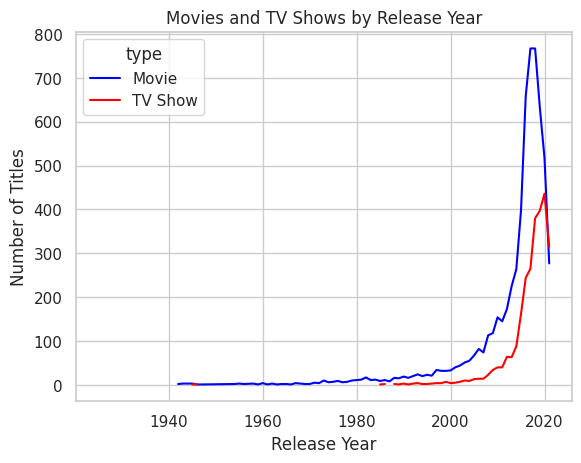

In [ ]:
# Movie and TV Show release trends (For the country chart, exclude Unknown values to see actual countries:)
df.groupby(['release_year', 'type']).size().unstack().plot(color=['blue', 'red'])

plt.title('Movies and TV Shows by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

Learn: How has the number of movies and TV shows changed over time?

# Netflix Data Analysis (EDA)

In [ ]:
df['listed_in'].str.split(', ').explode().value_counts().head(10)

,count
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


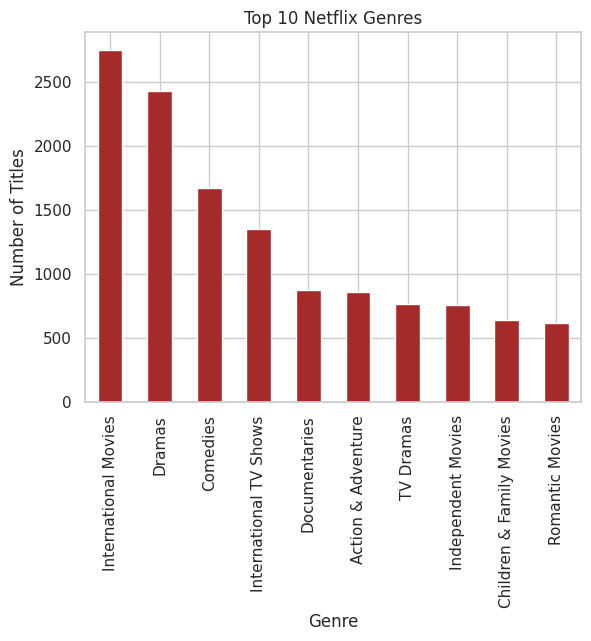

In [ ]:
df['listed_in'].str.split(', ').explode().value_counts().head(10).plot(kind='bar',color='brown')

plt.title('Top 10 Netflix Genres')
plt.xlabel('Genre')
plt.ylabel('Number of Titles')
plt.show()

Question: Which genre has the highest number of titles?

In [ ]:
# Top 10 Director
df[df['director'] != 'Unknown']['director'].value_counts().head(10)

,count
director,
Rajiv Chilaka,19
"Raúl Campos, Jan Suter",18
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,14
Cathy Garcia-Molina,13
Martin Scorsese,12
Youssef Chahine,12
Jay Chapman,12


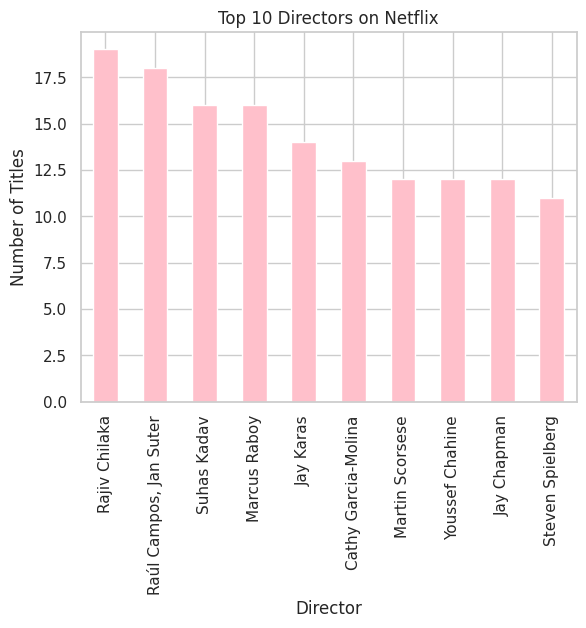

In [ ]:
df[df['director'] != 'Unknown']['director'].value_counts().head(10).plot(kind='bar',color='pink')
plt.title('Top 10 Directors on Netflix')
plt.xlabel('Director')
plt.ylabel('Number of Titles')
plt.show()

Question: Which director has the most titles?

In [ ]:
# Movie Duration Analysis
movies = df[df['type'] == 'Movie'].copy()

In [ ]:
# separate duration
movies['duration_number'] = movies['duration'].str.extract(r'(\d+)').astype(float)

In [ ]:
# find average
movies['duration_number'].mean()

np.float64(99.57718668407311)

In [ ]:
# TV Show Seasons Analysis
tv = df[df['type'] == 'TV Show'].copy()

tv['seasons'] = tv['duration'].str.extract(r'(\d+)').astype(float)

In [ ]:
tv['seasons'].value_counts().head(10)

,count
seasons,
1.0,1793
2.0,425
3.0,199
4.0,95
5.0,65
6.0,33
7.0,23
8.0,17
9.0,9


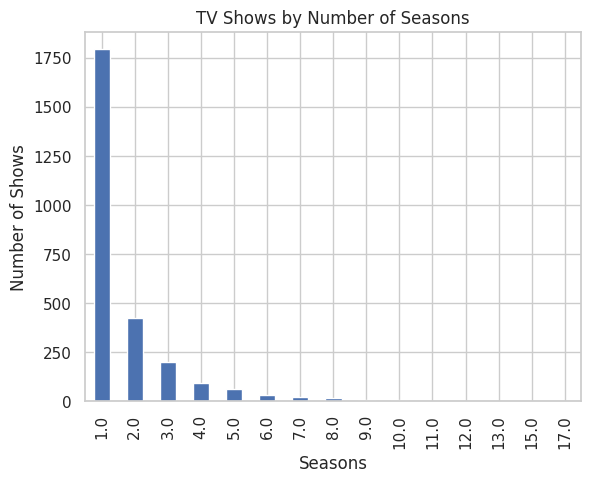

In [ ]:
tv['seasons'].value_counts().sort_index().plot(kind='bar')

plt.title('TV Shows by Number of Seasons')
plt.xlabel('Seasons')
plt.ylabel('Number of Shows')
plt.show()

Question: Which number of seasons is most common?

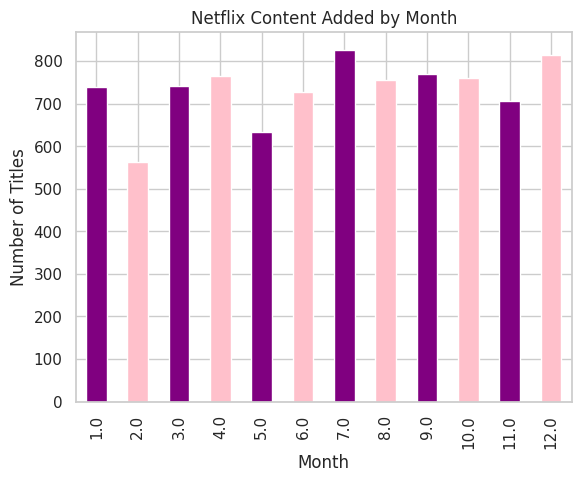

In [ ]:
df['month_added'].value_counts().sort_index().plot(kind='bar',color= ['purple','pink'])

plt.title('Netflix Content Added by Month')
plt.xlabel('Month')
plt.ylabel('Number of Titles')
plt.show()

Question: Which month has the highest number of additions?

# Advanced Netflix Data Analysis

In [ ]:
# Movies vs TV Shows by rating
df.groupby(['rating', 'type']).size().unstack().fillna(0)

type,Movie,TV Show
rating,,
66 min,1.0,0.0
74 min,1.0,0.0
84 min,1.0,0.0
G,41.0,0.0
NC-17,3.0,0.0
NR,75.0,5.0
PG,287.0,0.0
PG-13,490.0,0.0
R,797.0,2.0


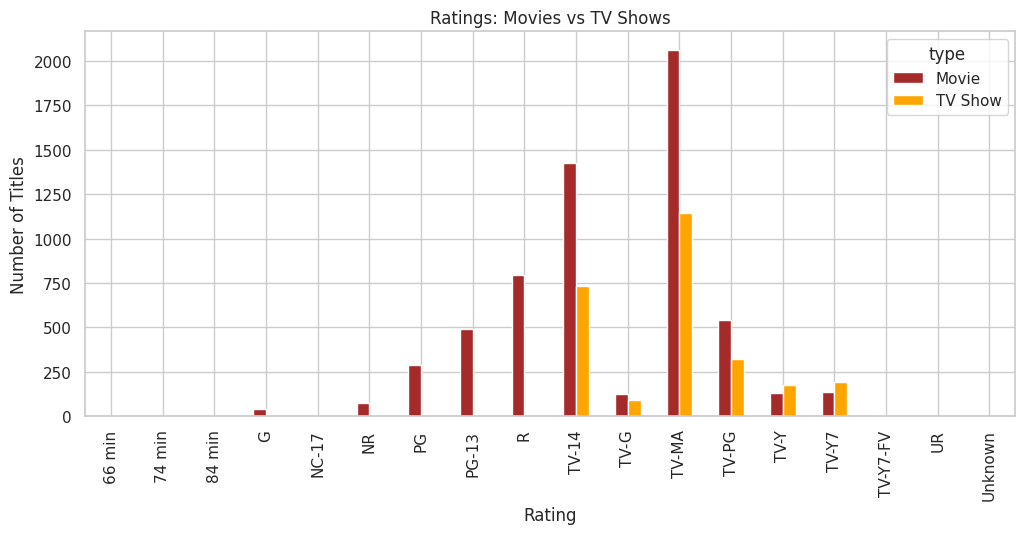

In [ ]:
df.groupby(['rating', 'type']).size().unstack().plot(kind='bar',color=['brown', 'orange', 'blue'], figsize=(12,5))

plt.title('Ratings: Movies vs TV Shows')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.show()

Question: Which rating is most common for Movies and TV Shows?

In [ ]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,9.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,9.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,9.0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,9.0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,9.0


In [ ]:
movies['duration_number'].describe()

,duration_number
count,6128.000000
mean,99.577187
std,28.290593
min,3.000000
25%,87.000000
50%,98.000000
75%,114.000000
max,312.000000


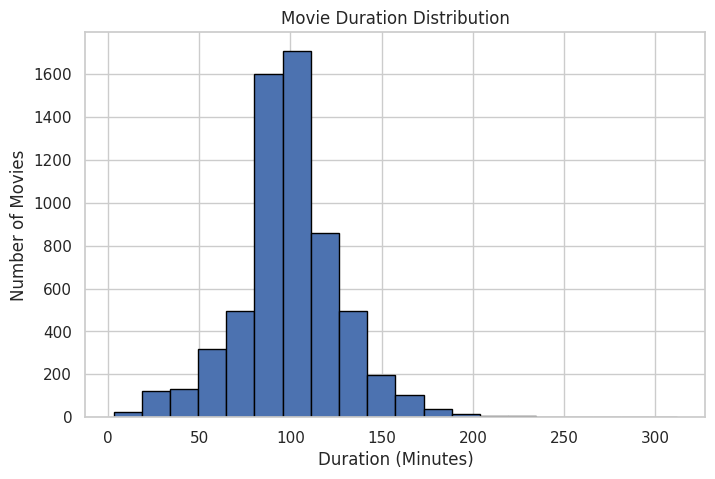

In [ ]:
movies['duration_number'].plot(kind='hist', bins=20, edgecolor='black', figsize=(8,5))

plt.title('Movie Duration Distribution')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')
plt.show()

Question: Which movie duration range appears most frequently?

In [ ]:
# Top 10 Countries by Movies
df[(df['type'] == 'Movie') & (df['country'] != 'Unknown')]['country'].value_counts().head(10)

,count
country,
United States,2058
India,893
United Kingdom,206
Canada,122
Spain,97
Egypt,92
Nigeria,86
Indonesia,77
Japan,76


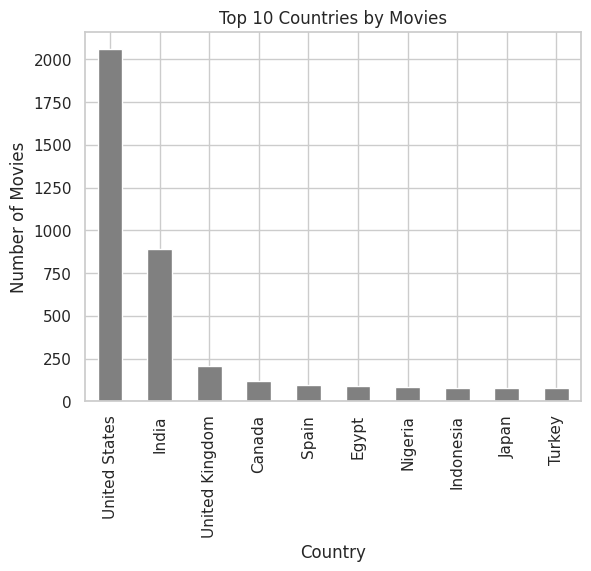

In [ ]:
df[(df['type'] == 'Movie') & (df['country'] != 'Unknown')]['country'].value_counts().head(10).plot(kind='bar',color='grey')

plt.title('Top 10 Countries by Movies')
plt.xlabel('Country')
plt.ylabel('Number of Movies')
plt.show()

Question: Which country has the most Movies?

In [ ]:
# Top 10 Countries by TV shows
df[(df['type'] == 'TV Show') & (df['country'] != 'Unknown')]['country'].value_counts().head(10)

,count
country,
United States,760
United Kingdom,213
Japan,169
South Korea,158
India,79
Taiwan,68
Canada,59
France,49
Australia,48


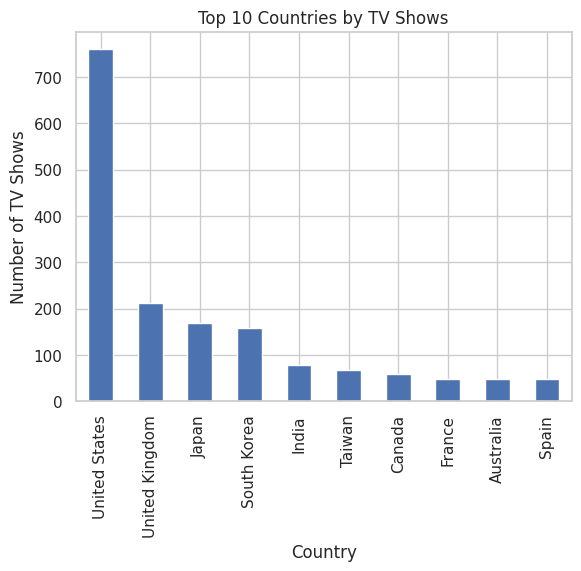

In [ ]:
df[(df['type'] == 'TV Show') & (df['country'] != 'Unknown')]['country'].value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Countries by TV Shows')
plt.xlabel('Country')
plt.ylabel('Number of TV Shows')
plt.show()

Question: Which country has the most TV Shows?

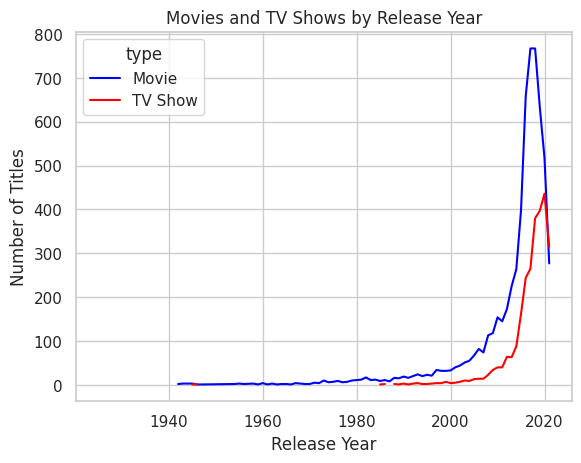

In [ ]:
# Movies and TV Shows added each year
df.groupby(['release_year', 'type']).size().unstack().plot(color=['blue', 'red'])

plt.title('Movies and TV Shows by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()


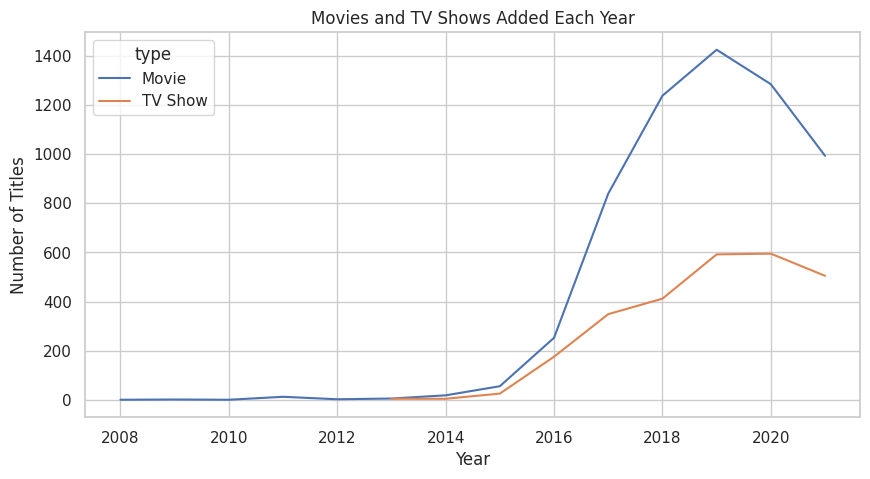

In [ ]:
df.groupby(['year_added', 'type']).size().unstack().plot(figsize=(10,5))

plt.title('Movies and TV Shows Added Each Year')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.show()

Question: Which type of content increased more over the years?

# Feature Engineering

In [ ]:
# Create content category
df['content_category'] = df['type'].map({
    'Movie': 'Film',
    'TV Show': 'Series'
})

df[['type', 'content_category']].head()

,type,content_category
0,Movie,Film
1,TV Show,Series
2,TV Show,Series
3,TV Show,Series
4,TV Show,Series


In [ ]:
# Extract duration number and unit
df['duration_number'] = df['duration'].str.extract(r'(\d+)')

df['duration_unit'] = df['duration'].str.extract(r'([A-Za-z]+)')

In [ ]:
df[['title', 'duration', 'duration_number', 'duration_unit']].head(10)

,title,duration,duration_number,duration_unit
0,Dick Johnson Is Dead,90 min,90,min
1,Blood & Water,2 Seasons,2,Seasons
2,Ganglands,1 Season,1,Season
3,Jailbirds New Orleans,1 Season,1,Season
4,Kota Factory,2 Seasons,2,Seasons
5,Midnight Mass,1 Season,1,Season
6,My Little Pony: A New Generation,91 min,91,min
7,Sankofa,125 min,125,min
8,The Great British Baking Show,9 Seasons,9,Seasons
9,The Starling,104 min,104,min


In [ ]:
# Count words in titles
df['title_word_count'] = df['title'].str.split().str.len()

df[['title', 'title_word_count']].head(10)

,title,title_word_count
0,Dick Johnson Is Dead,4
1,Blood & Water,3
2,Ganglands,1
3,Jailbirds New Orleans,3
4,Kota Factory,2
5,Midnight Mass,2
6,My Little Pony: A New Generation,6
7,Sankofa,1
8,The Great British Baking Show,5
9,The Starling,2


In [ ]:
# create release decade (Example: 2019 becomes 2010)
df['release_decade'] = (df['release_year'] // 10) * 10

df[['title', 'release_year', 'release_decade']].head(10)

,title,release_year,release_decade
0,Dick Johnson Is Dead,2020,2020
1,Blood & Water,2021,2020
2,Ganglands,2021,2020
3,Jailbirds New Orleans,2021,2020
4,Kota Factory,2021,2020
5,Midnight Mass,2021,2020
6,My Little Pony: A New Generation,2021,2020
7,Sankofa,1993,1990
8,The Great British Baking Show,2021,2020
9,The Starling,2021,2020


In [ ]:
df['release_decade'].value_counts().sort_index()

,count
release_decade,
1920,1
1940,15
1950,11
1960,25
1970,70
1980,129
1990,274
2000,810
2010,5927


In [ ]:
# Description length
df['description_length'] = df['description'].str.len()

df[['title', 'description_length']].head(10)

,title,description_length
0,Dick Johnson Is Dead,152
1,Blood & Water,147
2,Ganglands,146
3,Jailbirds New Orleans,147
4,Kota Factory,152
5,Midnight Mass,152
6,My Little Pony: A New Generation,153
7,Sankofa,151
8,The Great British Baking Show,144
9,The Starling,151


In [ ]:
df['description_length'].mean()

np.float64(143.3032814806404)

In [ ]:
# final verification
df.shape

(8807, 20)

In [ ]:
df[['content_category', 'duration_number',
    'duration_unit', 'title_word_count',
    'release_decade', 'description_length']].head()

,content_category,duration_number,duration_unit,title_word_count,release_decade,description_length
0,Film,90,min,4,2020,152
1,Series,2,Seasons,3,2020,147
2,Series,1,Season,1,2020,146
3,Series,1,Season,3,2020,147
4,Series,2,Seasons,2,2020,152


# Categorical Data Encoding

In [ ]:
# Understand categorical columns
df.select_dtypes(include='object').columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'rating',
       'duration', 'listed_in', 'description', 'content_category',
       'duration_number', 'duration_unit'],
      dtype='object')

In [ ]:
df['type'].unique()

array(['Movie', 'TV Show'], dtype=object)

TV Sh is a typo. It should be TV Show.
Correct it before encoding

In [ ]:
df['type'] = df['type'].replace({
    'TV Sh': 'TV Show'
})

In [ ]:
df['type'].unique()

array(['Movie', 'TV Show'], dtype=object)

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['type_encoded'] = le.fit_transform(df['type'])

df[['type', 'type_encoded']].head(10)

,type,type_encoded
0,Movie,0
1,TV Show,1
2,TV Show,1
3,TV Show,1
4,TV Show,1
5,TV Show,1
6,Movie,0
7,Movie,0
8,TV Show,1
9,Movie,0


In [ ]:
dict(zip(le.classes_, le.transform(le.classes_)))

{'Movie': np.int64(0), 'TV Show': np.int64(1)}

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)

encoded_data = encoder.fit_transform(df[['type']])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(['type']),
    index=df.index
)

df = pd.concat([df, encoded_df], axis=1)

df[['type', 'type_Movie', 'type_TV Show']].head(10)

,type,type_Movie,type_TV Show
0,Movie,1.0,0.0
1,TV Show,0.0,1.0
2,TV Show,0.0,1.0
3,TV Show,0.0,1.0
4,TV Show,0.0,1.0
5,TV Show,0.0,1.0
6,Movie,1.0,0.0
7,Movie,1.0,0.0
8,TV Show,0.0,1.0
9,Movie,1.0,0.0


In [ ]:
df.shape

(8807, 23)

In [ ]:
df[['type', 'type_encoded', 'type_Movie', 'type_TV Show']].head()

,type,type_encoded,type_Movie,type_TV Show
0,Movie,0,1.0,0.0
1,TV Show,1,0.0,1.0
2,TV Show,1,0.0,1.0
3,TV Show,1,0.0,1.0
4,TV Show,1,0.0,1.0


In [ ]:
df['type'].value_counts(dropna=False)

,count
type,
Movie,6131
TV Show,2676


In [ ]:
df.shape

(8807, 23)

In [ ]:
print(df.shape)
print(df['type'].value_counts())
df.info()

(8807, 23)
type
Movie      6131
TV Show    2676
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   show_id             8807 non-null   object        
 1   type                8807 non-null   object        
 2   title               8807 non-null   object        
 3   director            8807 non-null   object        
 4   cast                8807 non-null   object        
 5   country             8807 non-null   object        
 6   date_added          8797 non-null   datetime64[ns]
 7   release_year        8807 non-null   int64         
 8   rating              8807 non-null   object        
 9   duration            8807 non-null   object        
 10  listed_in           8807 non-null   object        
 11  description         8807 non-null   object        
 12  year_added          8797 non-n

# Numerical Data Scaling

In [ ]:
num_df = df[[
    'release_year',
    'title_word_count',
    'release_decade',
    'description_length'
]].copy()

num_df.head()

,release_year,title_word_count,release_decade,description_length
0,2020,4,2020,152
1,2021,3,2020,147
2,2021,1,2020,146
3,2021,3,2020,147
4,2021,2,2020,152


In [ ]:
num_df.describe()

,release_year,title_word_count,release_decade,description_length
count,8807.000000,8807.000000,8807.000000,8807.000000
mean,2014.180198,3.110821,2009.108664,143.303281
std,8.819312,1.862154,9.228119,10.334959
min,1925.000000,1.000000,1920.000000,61.000000
25%,2013.000000,2.000000,2010.000000,140.000000
50%,2017.000000,3.000000,2010.000000,146.000000
75%,2019.000000,4.000000,2010.000000,149.000000
max,2021.000000,17.000000,2020.000000,248.000000


In [ ]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler()

minmax_data = minmax.fit_transform(num_df)

minmax_df = pd.DataFrame(
    minmax_data,
    columns=num_df.columns,
    index=num_df.index
)

minmax_df.head()

,release_year,title_word_count,release_decade,description_length
0,0.989583,0.1875,1.0,0.486631
1,1.000000,0.1250,1.0,0.459893
2,1.000000,0.0000,1.0,0.454545
3,1.000000,0.1250,1.0,0.459893
4,1.000000,0.0625,1.0,0.486631


Question: Are the scaled values between 0 and 1?

In [ ]:
from sklearn.preprocessing import StandardScaler

standard = StandardScaler()

standard_data = standard.fit_transform(num_df)

standard_df = pd.DataFrame(
    standard_data,
    columns=num_df.columns,
    index=num_df.index
)

standard_df.head()

,release_year,title_word_count,release_decade,description_length
0,0.659930,0.477527,1.180301,0.841533
1,0.773324,-0.059516,1.180301,0.357711
2,0.773324,-1.133602,1.180301,0.260947
3,0.773324,-0.059516,1.180301,0.357711
4,0.773324,-0.596559,1.180301,0.841533


Question: Can you see negative and positive values?

In [ ]:
print("Original Data:")
print(num_df.head())

print("MinMax Scaled:")
print(minmax_df.head())

print("Standard Scaled:")
print(standard_df.head())

Original Data:
   release_year  title_word_count  release_decade  description_length
0          2020                 4            2020                 152
1          2021                 3            2020                 147
2          2021                 1            2020                 146
3          2021                 3            2020                 147
4          2021                 2            2020                 152
MinMax Scaled:
   release_year  title_word_count  release_decade  description_length
0      0.989583            0.1875             1.0            0.486631
1      1.000000            0.1250             1.0            0.459893
2      1.000000            0.0000             1.0            0.454545
3      1.000000            0.1250             1.0            0.459893
4      1.000000            0.0625             1.0            0.486631
Standard Scaled:
   release_year  title_word_count  release_decade  description_length
0      0.659930          0.477527        1.

In [ ]:
# Find the minimum and maximum values:
print(minmax_df.min())
print(minmax_df.max())

release_year          0.0
title_word_count      0.0
release_decade        0.0
description_length    0.0
dtype: float64
release_year          1.0
title_word_count      1.0
release_decade        1.0
description_length    1.0
dtype: float64


In [ ]:
# Find the mean of StandardScaler output:
standard_df.mean()

,0
release_year,7.564493e-15
title_word_count,-9.520159e-17
release_decade,9.139353e-15
description_length,-7.616127e-16


# Machine Learning: Classification

In [ ]:
# Understand Feature and target
# Features (X): Input columns used for prediction.
# Target (y): The output we want to predict.

X = df[[
    'release_year',
    'duration_number',
    'title_word_count',
    'description_length'
]].copy()

y = df['type']

print(X.head())
print(y.head())

   release_year duration_number  title_word_count  description_length
0          2020              90                 4                 152
1          2021               2                 3                 147
2          2021               1                 1                 146
3          2021               1                 3                 147
4          2021               2                 2                 152
0      Movie
1    TV Show
2    TV Show
3    TV Show
4    TV Show
Name: type, dtype: object


In [ ]:
# Convert duration into numerical data
X['duration_number'] = pd.to_numeric(
    X['duration_number'], errors='coerce'
)

In [ ]:
X.isnull().sum()

,0
release_year,0
duration_number,3
title_word_count,0
description_length,0


In [ ]:
# split the dataset
# divide data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(7045, 4)
(1762, 4)


In [ ]:
# Build a Logistic Regression model
# (We will use a Pipeline so missing-value handling and scaling are learned from training data only.)

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [ ]:
# make predictions
y_pred = model.predict(X_test)

print(y_pred[:10])

['Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'TV Show' 'Movie' 'TV Show'
 'TV Show' 'Movie']


In [ ]:
# Accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 1.0


# Model Evaluation

In [ ]:
# confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1227    0]
 [   0  535]]


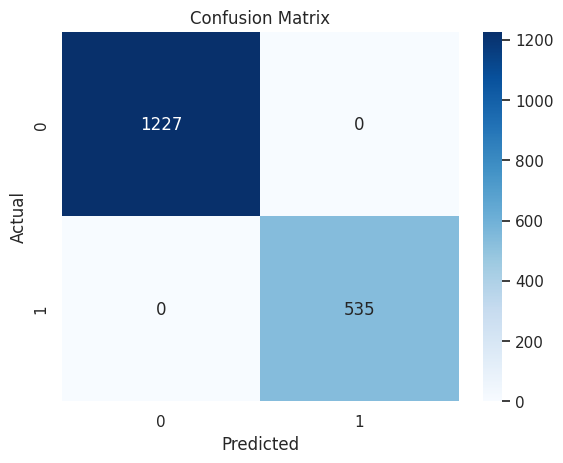

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1227
     TV Show       1.00      1.00      1.00       535

    accuracy                           1.00      1762
   macro avg       1.00      1.00      1.00      1762
weighted avg       1.00      1.00      1.00      1762



Metric	Meaning

Precision	How many predicted results were correct?

Recall	How many actual results were identified correctly?

F1-score	Balance between precision and recall

Support	Number of actual samples

In [ ]:
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test, y_pred))

1.0


In [ ]:
# check the data leakage
# Now remove duration_number and test the model again.

X2 = df[[
    'release_year',
    'title_word_count',
    'description_length'
]].copy()

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
model2 = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model2.fit(X_train2, y_train2)

y_pred2 = model2.predict(X_test2)

print("Accuracy:", accuracy_score(y_test2, y_pred2))

Accuracy: 0.699205448354143


# Decision Tree Classification

In [ ]:
# Important Decision Tree
from sklearn.tree import DecisionTreeClassifier

In [ ]:
dt_model = make_pipeline(
    SimpleImputer(strategy='median'),
    DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    )
)

dt_model.fit(X_train2, y_train2)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [ ]:
# make prediction
dt_pred = dt_model.predict(X_test2)

print(dt_pred[:10])

['Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie'
 'Movie']


In [ ]:
dt_accuracy = accuracy_score(y_test2, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.7082860385925085


In [ ]:
print(classification_report(y_test2, dt_pred))

              precision    recall  f1-score   support

       Movie       0.72      0.94      0.82      1227
     TV Show       0.56      0.17      0.26       535

    accuracy                           0.71      1762
   macro avg       0.64      0.56      0.54      1762
weighted avg       0.67      0.71      0.65      1762



In [ ]:
print("Logistic Regression:", accuracy_score(y_test2, y_pred2))

print("Decision Tree:", dt_accuracy)

Logistic Regression: 0.699205448354143
Decision Tree: 0.7082860385925085


# Random Forest Classification

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf_model = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )
)

rf_model.fit(X_train2, y_train2)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('randomforestclassifier',
                 RandomForestClassifier(max_depth=5, random_state=42))])

In [ ]:
rf_pred = rf_model.predict(X_test2)

print(rf_pred[:10])

['Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie'
 'Movie']


In [ ]:
rf_accuracy = accuracy_score(y_test2, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.7088535754824064


In [ ]:
print(classification_report(y_test2, rf_pred))

              precision    recall  f1-score   support

       Movie       0.71      0.98      0.82      1227
     TV Show       0.64      0.10      0.17       535

    accuracy                           0.71      1762
   macro avg       0.67      0.54      0.49      1762
weighted avg       0.69      0.71      0.62      1762



In [ ]:
print("Logistic Regression:", accuracy_score(y_test2, y_pred2))

print("Decision Tree:", dt_accuracy)

print("Random Forest:", rf_accuracy)

Logistic Regression: 0.699205448354143
Decision Tree: 0.7082860385925085
Random Forest: 0.7088535754824064


# K-Nearest Neighbors (KNN)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
knn_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train2, y_train2)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier())])

Meaning:

- n_neighbors=5: Checks the 5 nearest data points.

- StandardScaler(): Scales numerical values.

- fit(): Trains the model.

In [ ]:
knn_pred = knn_model.predict(X_test2)

print(knn_pred[:10])

['Movie' 'Movie' 'Movie' 'TV Show' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie'
 'Movie']


In [ ]:
knn_accuracy = accuracy_score(y_test2, knn_pred)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.6640181611804767


In [ ]:
print(classification_report(y_test2, knn_pred))

              precision    recall  f1-score   support

       Movie       0.72      0.84      0.78      1227
     TV Show       0.41      0.26      0.32       535

    accuracy                           0.66      1762
   macro avg       0.57      0.55      0.55      1762
weighted avg       0.63      0.66      0.64      1762



In [ ]:
print("Logistic Regression:", accuracy_score(y_test2, y_pred2))
print("Decision Tree:", dt_accuracy)
print("Random Forest:", rf_accuracy)
print("KNN:", knn_accuracy)

Logistic Regression: 0.699205448354143
Decision Tree: 0.7082860385925085
Random Forest: 0.7088535754824064
KNN: 0.6640181611804767


# Compare all 4 ML models

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'KNN'
    ],
    'Accuracy': [
        accuracy_score(y_test2, y_pred2),
        dt_accuracy,
        rf_accuracy,
        knn_accuracy
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.699205
1,Decision Tree,0.708286
2,Random Forest,0.708854
3,KNN,0.664018


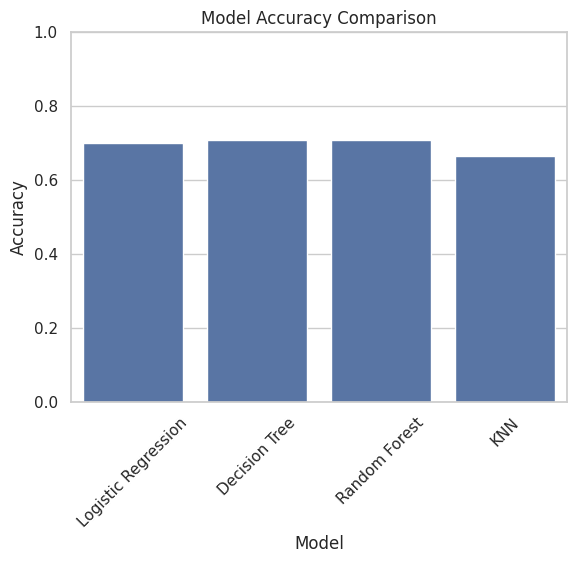

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(data=results, x='Model', y='Accuracy')

plt.title('Model Accuracy Comparison')
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.show()

In [ ]:
results.sort_values(
    by='Accuracy',
    ascending=False
)

,Model,Accuracy
2,Random Forest,0.708854
1,Decision Tree,0.708286
0,Logistic Regression,0.699205
3,KNN,0.664018


In [ ]:
df.shape


(8807, 23)

# Feature Importance (Random Forest)

In [ ]:
rf = rf_model.named_steps['randomforestclassifier']

importance_df = pd.DataFrame({
    'Feature': X_train2.columns,
    'Importance': rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
0,release_year,0.666189
2,description_length,0.191581
1,title_word_count,0.142230


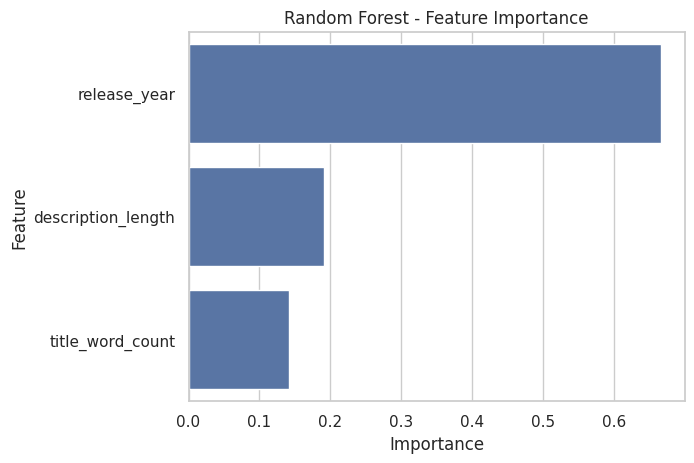

In [ ]:
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.show()

# Netflix Content Recommendation System

In [ ]:
recommend_df = df[['title', 'listed_in', 'description']].copy()

recommend_df.head()

,title,listed_in,description
0,Dick Johnson Is Dead,Documentaries,"As her father nears the end of his life, filmm..."
1,Blood & Water,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,Ganglands,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,Jailbirds New Orleans,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,Kota Factory,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
recommend_df['description'] = recommend_df['description'].fillna('')

recommend_df['listed_in'] = recommend_df['listed_in'].fillna('')

In [ ]:
recommend_df['content'] = (
    recommend_df['listed_in'] + ' ' +
    recommend_df['description']
)

In [ ]:
recommend_df[['title', 'content']].head()

,title,content
0,Dick Johnson Is Dead,Documentaries As her father nears the end of h...
1,Blood & Water,"International TV Shows, TV Dramas, TV Mysterie..."
2,Ganglands,"Crime TV Shows, International TV Shows, TV Act..."
3,Jailbirds New Orleans,"Docuseries, Reality TV Feuds, flirtations and ..."
4,Kota Factory,"International TV Shows, Romantic TV Shows, TV ..."


# TF-IDF Vectorization

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
tfidf = TfidfVectorizer(stop_words='english')

tfidf_matrix = tfidf.fit_transform(recommend_df['content'])

In [ ]:
tfidf_matrix.shape

(8807, 18895)

In [ ]:
print(tfidf.get_feature_names_out()[:20])

['000' '007' '009' '10' '100' '1000' '102' '108' '10th' '11' '112' '11th'
 '12' '12th' '13' '130' '13th' '14' '1402' '14th']


# Cosine Similarity

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
similarity = cosine_similarity(tfidf_matrix)

In [ ]:
similarity.shape

(8807, 8807)

In [ ]:
similarity[0][1]

np.float64(0.0)

In [ ]:
recommend_df['title'].head()

,title
0,Dick Johnson Is Dead
1,Blood & Water
2,Ganglands
3,Jailbirds New Orleans
4,Kota Factory


# Build Netflix Recommendation Function

In [ ]:
def recommend(title):
    match = recommend_df[
        recommend_df['title'].str.lower() == title.lower()
    ]

    if match.empty:
        print("Title not found in Netflix dataset!")
        return

    index = match.index[0]

    scores = list(enumerate(similarity[index]))
    scores = sorted(scores, key=lambda x: x[1], reverse=True)

    for i in scores[1:6]:
        print(recommend_df.iloc[i[0]]['title'])

In [ ]:
recommend('Stranger Things')

Rowdy Rathore
The OA
Sakho & Mangane
Star-Crossed
Manifest


In [ ]:
recommend('The Crown')

Ripper Street
Dad's Army
Elizabeth and Margaret: Love and Loyalty
Traitors
Historia de un clan


In [ ]:
recommend('death note')

Notes for My Son
Ghost House
海的儿子
Inhuman Kiss
DEATH NOTE


In [ ]:
recommend('squid game')

Free to Play
Nailed It! Mexico
Alice in Borderland
Sparta
Murder Among the Mormons


 # Improve Netflix Recommendation System

In [ ]:
print(df.shape)
print(recommend_df.shape)
print(similarity.shape)

(8807, 23)
(8807, 4)
(8807, 8807)


In [ ]:
# improve the recommend function
def recommend(title):

    match = recommend_df[
        recommend_df['title'].str.lower() == title.lower()
    ]

    if match.empty:
        print("Title not found!")
        return

    index = match.index[0]

    scores = list(enumerate(similarity[index]))

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    scores = scores[1:6]

    recommendations = []

    for i in scores:
        recommendations.append({
            'Title': recommend_df.iloc[i[0]]['title'],
            'Similarity Score': round(i[1], 3)
        })

    return pd.DataFrame(recommendations)

In [ ]:
recommend('Stranger Things')

,Title,Similarity Score
0,Rowdy Rathore,0.275
1,The OA,0.260
2,Sakho & Mangane,0.232
3,Star-Crossed,0.231
4,Manifest,0.229


In [ ]:
recommend('Money Heist')

Title not found!


# Test Your Netflix Recommendation System

In [ ]:
recommend('Stranger Things')

,Title,Similarity Score
0,Rowdy Rathore,0.275
1,The OA,0.260
2,Sakho & Mangane,0.232
3,Star-Crossed,0.231
4,Manifest,0.229


In [ ]:
recommend('Money Heist')

Title not found!


In [ ]:
recommend('The Crown')

,Title,Similarity Score
0,Ripper Street,0.218
1,Dad's Army,0.209
2,Elizabeth and Margaret: Love and Loyalty,0.207
3,Traitors,0.206
4,Historia de un clan,0.199


In [ ]:
recommend('Breaking Bad')

,Title,Similarity Score
0,Extracurricular,0.230
1,Iron Ladies,0.222
2,"Have You Ever Fallen in Love, Miss Jiang?",0.203
3,Sparta,0.200
4,The Mess You Leave Behind,0.199


In [ ]:
recommend('Dark')

,Title,Similarity Score
0,Who Killed Sara?,0.260
1,THE STRANGER,0.259
2,Altered Carbon,0.254
3,Love Rain,0.244
4,Sophie: A Murder in West Cork,0.227


In [ ]:
result = recommend('Stranger Things')

result

,Title,Similarity Score
0,Rowdy Rathore,0.275
1,The OA,0.260
2,Sakho & Mangane,0.232
3,Star-Crossed,0.231
4,Manifest,0.229


In [ ]:
result['Similarity Score'].max()

0.275

In [ ]:
result['Similarity Score'].mean()

np.float64(0.2454)

In [ ]:
recommend('Avengers')

Title not found!


# Build a Netflix Recommendation Interface

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

In [ ]:
#Create a search box and button
search_box = widgets.Text(
    placeholder='Enter Netflix title',
    description='Title:'
)

search_button = widgets.Button(
    description='Recommend',
    button_style='success'
)

output = widgets.Output()

In [ ]:
#Create the button function
def show_recommendations(b):

    with output:
        clear_output()

        title = search_box.value.strip()

        if title == '':
            print("Please enter a Netflix title!")
            return

        result = recommend(title)

        if result is not None:
            display(result)

In [ ]:
#Connect the button
search_button.on_click(show_recommendations)

In [ ]:
#Display your interface
display(search_box, search_button, output)

Text(value='inception', description='Title:', placeholder='Enter Netflix title')

Button(button_style='success', description='Recommend', style=ButtonStyle())

Output()

# Create Netflix Project Visualizations

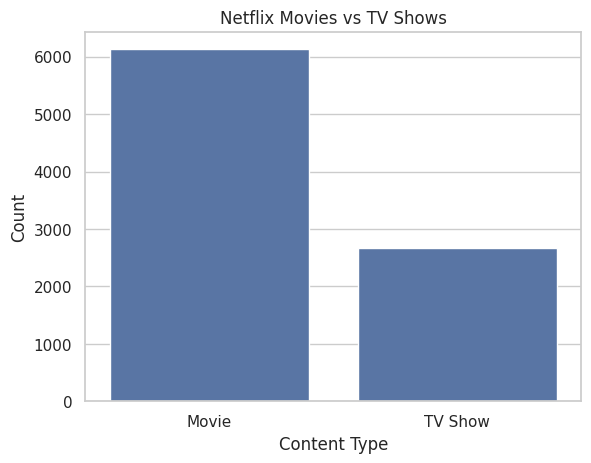

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='type')

plt.title('Netflix Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Count')
plt.show()

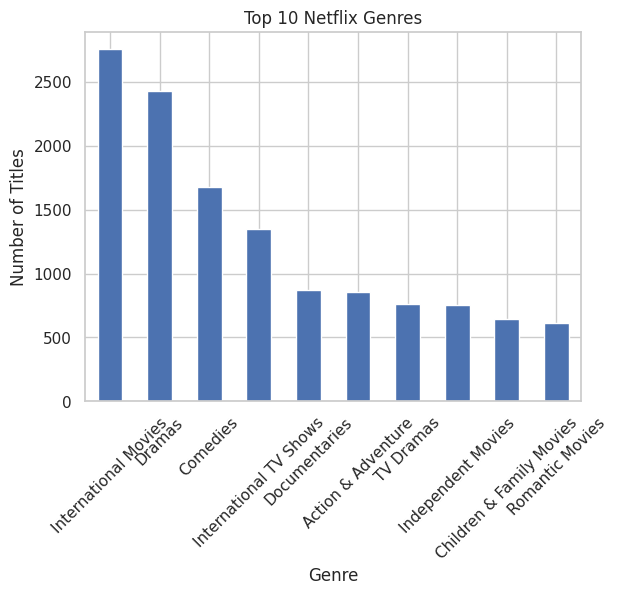

In [ ]:
top_genres = (
    df['listed_in']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

top_genres.plot(kind='bar')

plt.title('Top 10 Netflix Genres')
plt.xlabel('Genre')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.show()

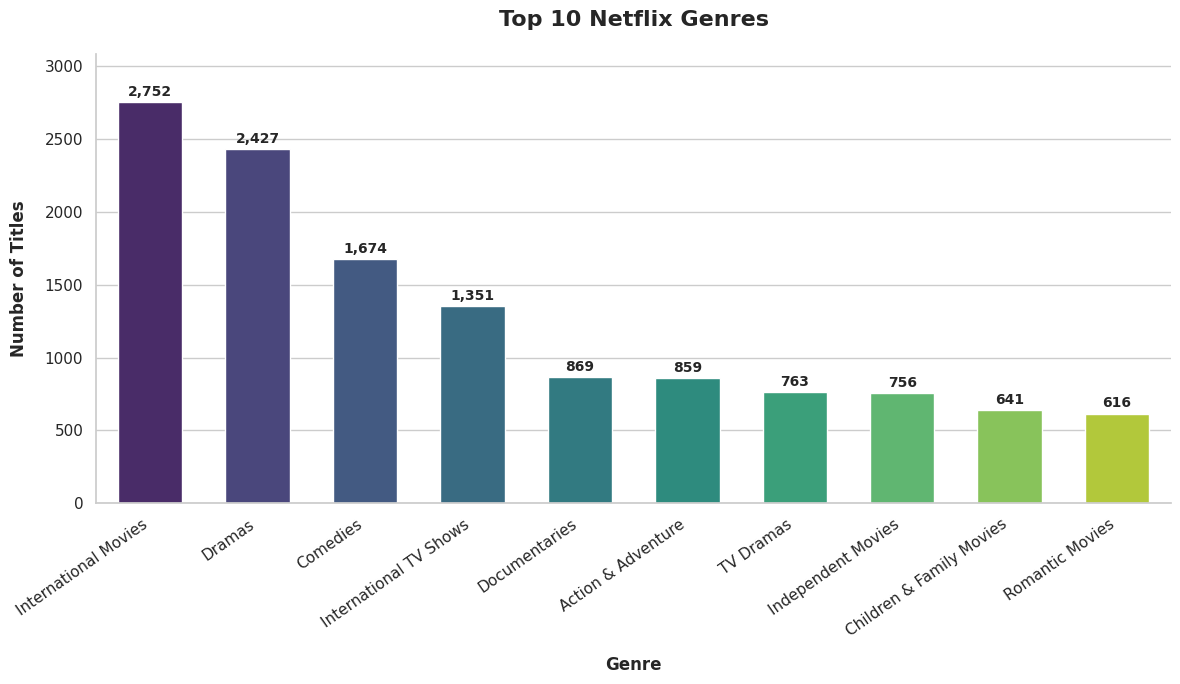

In [ ]:
# modify the above graph

# 1. Extract and count the top 10 genres
top_genres = (
    df['listed_in']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

# 2. Make the figure larger for plenty of space
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# 3. Create a colorful bar plot using Seaborn
ax = sns.barplot(
    x=top_genres.index,
    y=top_genres.values,
    hue=top_genres.index,
    palette="viridis",  # Try "Set2", "Spectral", or "coolwarm" for different colors
    legend=False,
    width=0.6           # Adds space between the bars
)

# 4. Add exact count numbers above each bar
for i, val in enumerate(top_genres.values):
    ax.text(i, val + (top_genres.max() * 0.015), f'{val:,}',
            ha='center', fontsize=10, fontweight='bold')

# 5. Add titles, labels, and extra top headroom
plt.title('Top 10 Netflix Genres', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Genre', fontsize=12, fontweight='bold', labelpad=12)
plt.ylabel('Number of Titles', fontsize=12, fontweight='bold', labelpad=12)
plt.xticks(rotation=35, ha='right', fontsize=11)
plt.ylim(0, top_genres.max() * 1.12)  # Prevents top numbers from touching the edge

sns.despine()
plt.tight_layout()
plt.show()


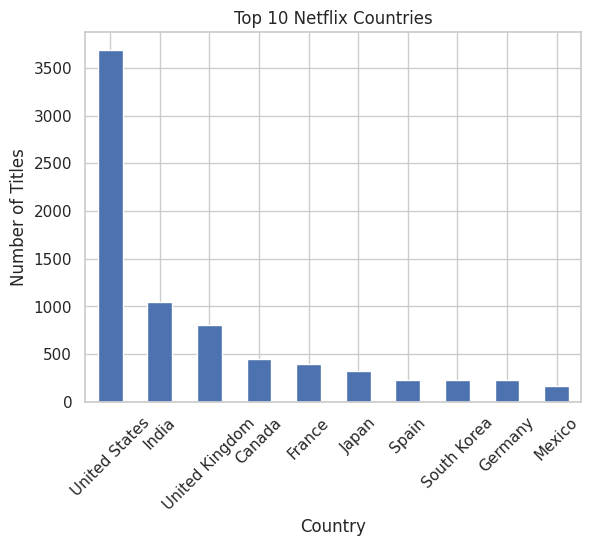

In [ ]:
top_countries = (
    df[df['country'] != 'Unknown']['country']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

top_countries.plot(kind='bar')

plt.title('Top 10 Netflix Countries')
plt.xlabel('Country')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.show()

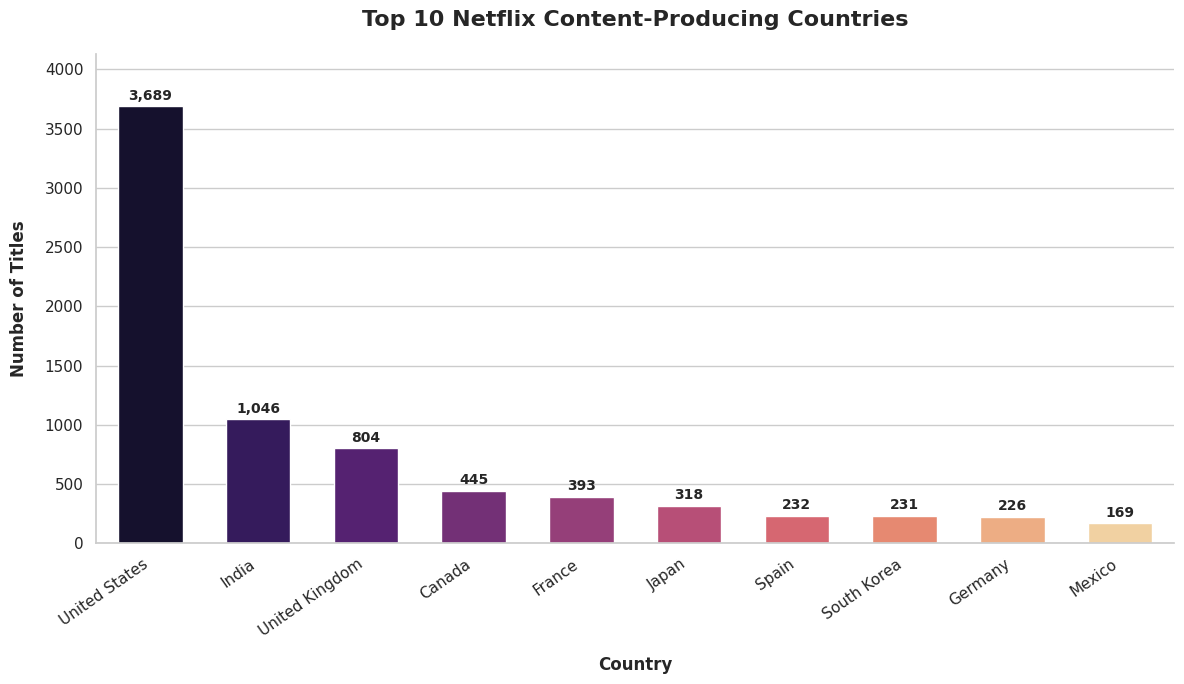

In [ ]:
# modify the above graph

# 1. Extract and count top 10 countries
top_countries = (
    df[df['country'] != 'Unknown']['country']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

# 2. Set larger canvas size and clean theme
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# 3. Draw colorful bar chart with spacing between bars
ax = sns.barplot(
    x=top_countries.index,
    y=top_countries.values,
    hue=top_countries.index,
    palette="magma",    # Vibrant gradient palette
    legend=False,
    width=0.6
)

# 4. Add exact count labels above each bar
for i, val in enumerate(top_countries.values):
    ax.text(i, val + (top_countries.max() * 0.015), f'{val:,}',
            ha='center', fontsize=10, fontweight='bold')

# 5. Add spacious titles, labels, and headroom
plt.title('Top 10 Netflix Content-Producing Countries', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Country', fontsize=12, fontweight='bold', labelpad=12)
plt.ylabel('Number of Titles', fontsize=12, fontweight='bold', labelpad=12)
plt.xticks(rotation=35, ha='right', fontsize=11)
plt.ylim(0, top_countries.max() * 1.12)

sns.despine()
plt.tight_layout()
plt.show()


In [ ]:
result = recommend('Inception')

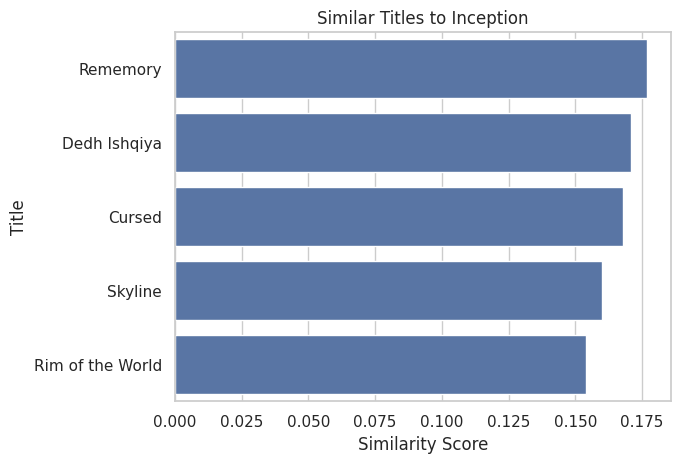

In [ ]:
sns.barplot(
    data=result,
    x='Similarity Score',
    y='Title'
)

plt.title('Similar Titles to Inception')
plt.show()

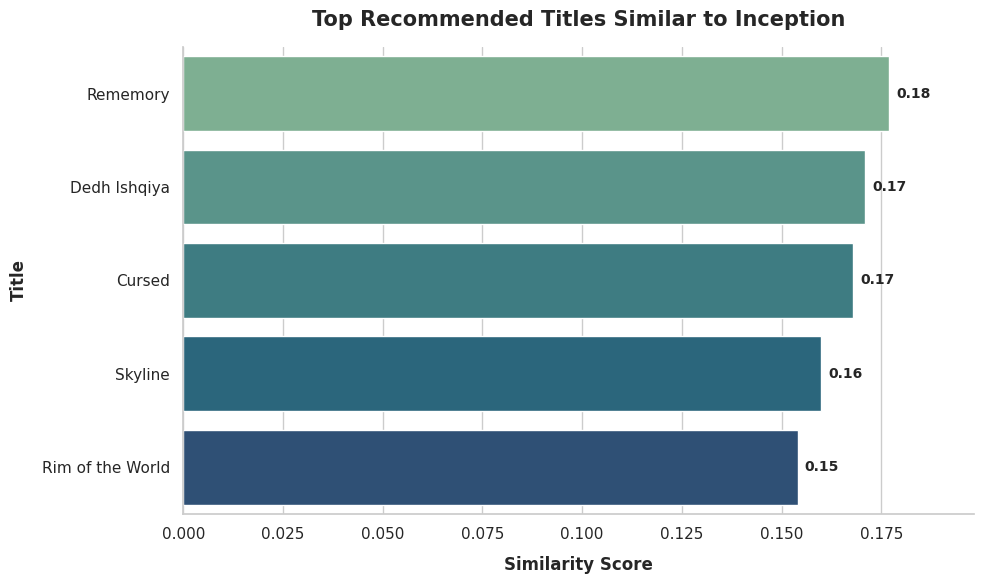

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Make the figure larger for clean spacing
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 2. Draw a colorful horizontal bar plot
ax = sns.barplot(
    data=result,
    x='Similarity Score',
    y='Title',
    hue='Title',
    palette='crest',
    legend=False
)

# 3. Print the exact score next to the end of each bar
for i, val in enumerate(result['Similarity Score']):
    ax.text(val + (result['Similarity Score'].max() * 0.01), i, f'{val:.2f}',
            va='center', fontsize=10, fontweight='bold')

# 4. Add title, labels, and extra right-side space
plt.title('Top Recommended Titles Similar to Inception', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Similarity Score', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Title', fontsize=12, fontweight='bold', labelpad=10)
plt.xlim(0, result['Similarity Score'].max() * 1.12)

sns.despine()
plt.tight_layout()
plt.show()


In [ ]:
result.to_csv(
    'inception_recommendations.csv',
    index=False
)

In [ ]:
from google.colab import files

files.download('inception_recommendations.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>